# IQL en GPU: entrenamiento y búsqueda de hiperparámetros

Este notebook:
1. Hace una **búsqueda aleatoria de arquitectura/entrenamiento** (etapa 1) con τ=0,9, β=3, γ=0,9.
2. Hace la **grilla IQL de τ, β y γ** (etapa 2) sobre la mejor arquitectura, incluyendo γ=0 frente a γ>0.
3. Entrena **3 semillas** con la configuración elegida y evalúa **π** y **máximo de Q** en validación frente a las líneas base ajustadas con los mismos logs.
4. Deja **test reservado** (`RUN_TEST = False`).

Pensado para una VM con GPU NVIDIA A30 (24 GB), 128 cores y 396 GB de RAM. Usa `modelos/iql.py` con AMP (fp16) y TF32. La evaluación del protocolo es secuencial (un forward batch-1 por paso de sesión): el entrenamiento es rápido, la evaluación es el cuello.

Para una prueba rápida de punta a punta, poner `SMOKE = True`.

Las decisiones de diseño del modelo (codificadores separados, recompensa centrada, red objetivo, checkpoint de la última época, etc.) están documentadas en `modelos/iql.py` y en la guía del TP.

In [1]:
SMOKE = False

DATASET = "netflix"
LOGS = "random"          # "random" | "mixto" | "experto"
HORIZON = 20
RUN_NAME = "iql_gpu_smoke" if SMOKE else f"iql_gpu_{LOGS}"

HPO_TRIALS = 1 if SMOKE else 8
HPO_PER_GROUP = 2 if SMOKE else 25
HPO_CONDITIONS = [(0, True), (0, False)]
MAX_BATCHES = 3 if SMOKE else None

STAGE1_IQL = dict(tau=0.9, beta=3.0, gamma=0.9)
FIXED_TRAIN = dict(group_dropout=0.3)
GRID_TAU = (0.9,) if SMOKE else (0.7, 0.9)
GRID_BETA = (3.0,) if SMOKE else (3.0, 10.0)
GRID_GAMMA = (0.9,) if SMOKE else (0.0, 0.9)

FINAL_SEEDS = (0,) if SMOKE else (0, 1, 2)
FINAL_PER_GROUP = 2 if SMOKE else 50
EVAL_SEEDS = (0,) if SMOKE else (0, 1, 2)

RUN_TEST = False

In [2]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if not (ROOT / "config_dataset.py").exists():
    raise RuntimeError("Ejecutar el notebook desde 2026/tp")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from modelos.iql import IQLPolicy, train_iql
from protocolo.datos import load_test, load_train, make_episodes, num_items, split_by_user
from protocolo.evaluar import baseline_factories, evaluate, write_reports
from protocolo.logs import PRESETS, PreviousSystem, logged_episodes, logs_cache
from protocolo.metricas import summarize
from protocolo.simulador import SessionConfig

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
if DEVICE == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

torch.manual_seed(0)
np.random.seed(0)
print(f"torch {torch.__version__} | device: {DEVICE} | amp: {USE_AMP}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
if SMOKE:
    print("MODO SMOKE: corrida corta para validar el notebook")

torch 2.15.0+cu132 | device: cuda | amp: True
NVIDIA A30


In [3]:
paths = Path(f"outputs/{RUN_NAME}")
paths.mkdir(parents=True, exist_ok=True)

train_all = load_train(DATASET)
train, val = split_by_user(train_all)
N_ITEMS = num_items(DATASET)

if LOGS == "random":
    train_ep = make_episodes(train, HORIZON)
    val_ep = make_episodes(val, HORIZON)
    baseline_train = train
else:
    logged_train = logged_episodes(
        LOGS, train, train, N_ITEMS, HORIZON, seed=0,
        cache=logs_cache(DATASET, LOGS, "train"),
    )
    logged_val = logged_episodes(
        LOGS, val, train, N_ITEMS, HORIZON, seed=1,
        cache=logs_cache(DATASET, LOGS, "val"),
    )
    train_ep, val_ep = logged_train.episodes, logged_val.episodes
    baseline_train = logged_train.logged_users()

print(f"logs: {LOGS} | catálogo: {N_ITEMS}")
print(f"episodios: train {train_ep.items.shape[0]:,} | val {val_ep.items.shape[0]:,}")
print("retorno medio de un episodio de train:", float(train_ep.ratings.sum(1).mean()))

logs: random | catálogo: 752
episodios: train 73,827 | val 8,275
retorno medio de un episodio de train: 64.29808877510938


In [4]:
def stratified_subset(users, per_group, seed=0):
    rng = np.random.default_rng(seed)
    subset = []
    for group in range(8):
        members = [u for u in users if u.group == group]
        take = min(per_group, len(members))
        idx = rng.choice(len(members), size=take, replace=False)
        subset.extend(members[i] for i in idx)
    return subset


def eval_policy(policy, users, conditions, seeds):
    frames = []
    for warmup, visible in conditions:
        cfg = SessionConfig(horizon=HORIZON, warmup=warmup, group_visible=visible)
        df = evaluate(policy, users, N_ITEMS, cfg, seeds=seeds)
        df["warmup"] = warmup
        df["group_visible"] = visible
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def eval_iql(model, users, conditions, seeds, modes=("pi", "q")):
    frames = []
    for mode in modes:
        df = eval_policy(IQLPolicy(model, mode), users, conditions, seeds)
        df["mode"] = mode
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


hpo_users = stratified_subset(val, HPO_PER_GROUP, seed=0)
final_users = stratified_subset(val, FINAL_PER_GROUP, seed=1)
print(f"usuarios de val: HPO {len(hpo_users)} | final {len(final_users)}")

usuarios de val: HPO 200 | final 400


## 1. Búsqueda de hiperparámetros: arquitectura y entrenamiento

Búsqueda aleatoria sobre `d_model`, `n_layers`, `n_heads`, `dropout`, `lr`, `weight_decay`, `batch_size` y `epochs`, con τ=0,9, β=3, γ=0,9 fijos. `group_dropout` se fija en 0,3 para que el token "grupo desconocido" se entrene y la condición cold-start sea válida.

Cada trial se entrena una vez y se evalúa en un subconjunto estratificado de validación (25 usuarios por grupo) con el protocolo: warm-up 0, grupo visible y oculto, políticas π y máximo de Q. El score es el **normalizado medio** de las dos políticas y las dos condiciones. Las pérdidas se guardan sólo como diagnóstico.

En la A30 el entrenamiento es rápido; el tiempo lo domina la evaluación del protocolo. Si hace falta acortar, bajar `HPO_TRIALS` o `HPO_PER_GROUP`.

In [5]:
rng = np.random.default_rng(123)


def sample_config():
    d_model = int(rng.choice([64, 96, 128]))
    head_options = [h for h in (4, 8) if d_model % h == 0]
    return {
        "d_model": d_model,
        "n_heads": int(rng.choice(head_options)),
        "n_layers": int(rng.choice([2, 3])),
        "dropout": float(rng.choice([0.0, 0.1, 0.2])),
        "lr": float(np.exp(rng.uniform(np.log(1e-4), np.log(1e-3)))),
        "weight_decay": float(rng.choice([1e-2, 1e-1])),
        "batch_size": int(rng.choice([256, 512, 1024])),
        "epochs": int(rng.choice([10, 15])),
    }


SMOKE_CONFIG = {
    "d_model": 32, "n_heads": 2, "n_layers": 1, "dropout": 0.0,
    "lr": 1e-3, "weight_decay": 1e-2, "batch_size": 32, "epochs": 1,
}

hpo_rows = []
for trial in range(HPO_TRIALS):
    cfg = SMOKE_CONFIG if SMOKE else sample_config()
    start = time.time()
    model, history = train_iql(
        train_ep, val_ep, N_ITEMS,
        seed=0,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "hpo" / f"trial{trial:02d}",
        verbose=not SMOKE,
        **cfg, **STAGE1_IQL, **FIXED_TRAIN,
    )
    raw = eval_iql(model, hpo_users, HPO_CONDITIONS, seeds=(0,))
    summary = summarize(raw, by=["mode", "warmup", "group_visible"])
    norm = summary[("normalized", "mean")]
    pi_score = float(norm.xs("pi", level="mode").mean())
    q_score = float(norm.xs("q", level="mode").mean())
    score = (pi_score + q_score) / 2
    row = {
        **cfg, **STAGE1_IQL, **FIXED_TRAIN,
        "pi": pi_score, "q": q_score, "score": score,
        "val_pi": float(history.iloc[-1]["val_pi"]),
        "minutos": (time.time() - start) / 60,
    }
    hpo_rows.append(row)
    print(
        f"trial {trial}: score={score:.3f} | pi={pi_score:.3f} q={q_score:.3f} "
        f"| {row['minutos']:.1f} min | {cfg}"
    )
    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

hpo = pd.DataFrame(hpo_rows).sort_values("score", ascending=False).reset_index(drop=True)
hpo.to_csv(paths / "hpo_resultados.csv", index=False)
hpo.round(4)

epoch   1/10 | V 0.0840 Q 0.9736 π 5.5207 | peso medio 0.85 (truncado 0.0%) | val π 5.1525
epoch   2/10 | V 0.0416 Q 0.4648 π 4.6080 | peso medio 0.74 (truncado 0.0%) | val π 4.3181
epoch   3/10 | V 0.0238 Q 0.3466 π 4.3228 | peso medio 0.69 (truncado 0.0%) | val π 4.4537
epoch   4/10 | V 0.0256 Q 0.3146 π 4.2918 | peso medio 0.69 (truncado 0.0%) | val π 3.7256
epoch   5/10 | V 0.0351 Q 0.3700 π 4.5660 | peso medio 0.73 (truncado 0.0%) | val π 4.0431
epoch   6/10 | V 0.0320 Q 0.3573 π 4.3950 | peso medio 0.71 (truncado 0.0%) | val π 5.6614
epoch   7/10 | V 0.0321 Q 0.3547 π 4.3839 | peso medio 0.71 (truncado 0.0%) | val π 4.9801
epoch   8/10 | V 0.0304 Q 0.3348 π 4.3286 | peso medio 0.70 (truncado 0.0%) | val π 4.4313
epoch   9/10 | V 0.0306 Q 0.3376 π 4.3328 | peso medio 0.70 (truncado 0.0%) | val π 4.3075
epoch  10/10 | V 0.0309 Q 0.3471 π 4.3785 | peso medio 0.71 (truncado 0.0%) | val π 4.4865
checkpoint e historial en outputs/iql_gpu_random/hpo/trial00
trial 0: score=0.557 | pi=0.5

/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/15 | V 0.1335 Q 1.3146 π 14.7838 | peso medio 2.20 (truncado 0.4%) | val π 4.5530
epoch   2/15 | V 0.0765 Q 0.6779 π 5.6073 | peso medio 0.89 (truncado 0.0%) | val π 4.6254
epoch   3/15 | V 0.0548 Q 0.4282 π 4.6633 | peso medio 0.77 (truncado 0.0%) | val π 4.2501
epoch   4/15 | V 0.0368 Q 0.3641 π 4.3227 | peso medio 0.71 (truncado 0.0%) | val π 4.0094
epoch   5/15 | V 0.0282 Q 0.3408 π 4.2817 | peso medio 0.69 (truncado 0.0%) | val π 4.2086
epoch   6/15 | V 0.0252 Q 0.3329 π 4.2925 | peso medio 0.69 (truncado 0.0%) | val π 4.3837
epoch   7/15 | V 0.0251 Q 0.3235 π 4.2917 | peso medio 0.69 (truncado 0.0%) | val π 4.1128
epoch   8/15 | V 0.0262 Q 0.3184 π 4.2886 | peso medio 0.69 (truncado 0.0%) | val π 4.0386
epoch   9/15 | V 0.0279 Q 0.3138 π 4.2938 | peso medio 0.69 (truncado 0.0%) | val π 3.9323
epoch  10/15 | V 0.0295 Q 0.3111 π 4.3041 | peso medio 0.69 (truncado 0.0%) | val π 3.9662
epoch  11/15 | V 0.0310 Q 0.3123 π 4.3175 | peso medio 0.70 (truncado 0.0%) | val π 3.861

/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/10 | V 0.0884 Q 0.9012 π 8.0801 | peso medio 1.23 (truncado 0.1%) | val π 4.2620
epoch   2/10 | V 0.0322 Q 0.3991 π 4.3612 | peso medio 0.70 (truncado 0.0%) | val π 4.0042
epoch   3/10 | V 0.0261 Q 0.3446 π 4.2993 | peso medio 0.69 (truncado 0.0%) | val π 4.5032
epoch   4/10 | V 0.0300 Q 0.3293 π 4.3260 | peso medio 0.70 (truncado 0.0%) | val π 3.8922
epoch   5/10 | V 0.0319 Q 0.3323 π 4.3305 | peso medio 0.70 (truncado 0.0%) | val π 3.8231
epoch   6/10 | V 0.0396 Q 0.3967 π 4.6291 | peso medio 0.75 (truncado 0.0%) | val π 6.2986
epoch   7/10 | V 0.0419 Q 0.4320 π 4.6692 | peso medio 0.76 (truncado 0.0%) | val π 2.7222
epoch   8/10 | V 0.0406 Q 0.4175 π 4.6028 | peso medio 0.75 (truncado 0.0%) | val π 4.5479
epoch   9/10 | V 0.0370 Q 0.3833 π 4.3623 | peso medio 0.71 (truncado 0.0%) | val π 3.6266
epoch  10/10 | V 0.0370 Q 0.3815 π 4.4205 | peso medio 0.72 (truncado 0.0%) | val π 3.7702
checkpoint e historial en outputs/iql_gpu_random/hpo/trial04
trial 4: score=0.578 | pi=0.5

/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/10 | V 0.0934 Q 0.9470 π 9.2060 | peso medio 1.39 (truncado 0.1%) | val π 4.9257
epoch   2/10 | V 0.0409 Q 0.4586 π 4.5642 | peso medio 0.73 (truncado 0.0%) | val π 4.1331
epoch   3/10 | V 0.0255 Q 0.3658 π 4.3238 | peso medio 0.69 (truncado 0.0%) | val π 4.2124
epoch   4/10 | V 0.0276 Q 0.3350 π 4.3177 | peso medio 0.70 (truncado 0.0%) | val π 3.8695
epoch   5/10 | V 0.0294 Q 0.3426 π 4.3430 | peso medio 0.70 (truncado 0.0%) | val π 3.7712
epoch   6/10 | V 0.0338 Q 0.3881 π 4.6219 | peso medio 0.74 (truncado 0.0%) | val π 2.5383
epoch   7/10 | V 0.0349 Q 0.4132 π 4.6256 | peso medio 0.74 (truncado 0.0%) | val π 4.6027
epoch   8/10 | V 0.0332 Q 0.4015 π 4.5810 | peso medio 0.74 (truncado 0.0%) | val π 4.6178
epoch   9/10 | V 0.0313 Q 0.3832 π 4.4408 | peso medio 0.71 (truncado 0.0%) | val π 3.7442
epoch  10/10 | V 0.0316 Q 0.3851 π 4.4808 | peso medio 0.72 (truncado 0.0%) | val π 3.8302
checkpoint e historial en outputs/iql_gpu_random/hpo/trial05
trial 5: score=0.555 | pi=0.5

/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/10 | V 0.0852 Q 0.7788 π 7.2469 | peso medio 1.13 (truncado 0.1%) | val π 4.6859
epoch   2/10 | V 0.0369 Q 0.3391 π 4.3074 | peso medio 0.71 (truncado 0.0%) | val π 3.9255
epoch   3/10 | V 0.0259 Q 0.3084 π 4.3206 | peso medio 0.69 (truncado 0.0%) | val π 5.2454
epoch   4/10 | V 0.0276 Q 0.3005 π 4.3006 | peso medio 0.69 (truncado 0.0%) | val π 4.1542
epoch   5/10 | V 0.0288 Q 0.2873 π 4.2709 | peso medio 0.69 (truncado 0.0%) | val π 4.4599
epoch   6/10 | V 0.0304 Q 0.2887 π 4.2740 | peso medio 0.69 (truncado 0.0%) | val π 4.0423
epoch   7/10 | V 0.0313 Q 0.2905 π 4.2771 | peso medio 0.69 (truncado 0.0%) | val π 4.3268
epoch   8/10 | V 0.0319 Q 0.2936 π 4.2836 | peso medio 0.70 (truncado 0.0%) | val π 4.1608
epoch   9/10 | V 0.0324 Q 0.2972 π 4.2835 | peso medio 0.70 (truncado 0.0%) | val π 4.3757
epoch  10/10 | V 0.0328 Q 0.3040 π 4.3275 | peso medio 0.70 (truncado 0.0%) | val π 4.5535
checkpoint e historial en outputs/iql_gpu_random/hpo/trial07
trial 7: score=0.587 | pi=0.5

,d_model,n_heads,n_layers,dropout,lr,weight_decay,batch_size,epochs,tau,beta,gamma,group_dropout,pi,q,score,val_pi,minutos
0,128,4,2,0.0,0.0005,0.10,512,10,0.9,3.0,0.9,0.3,0.5903,0.5829,0.5866,4.5535,3.6944
1,128,8,2,0.1,0.0002,0.01,256,10,0.9,3.0,0.9,0.3,0.5795,0.5775,0.5785,3.7702,2.8875
2,64,4,3,0.0,0.0008,0.10,1024,10,0.9,3.0,0.9,0.3,0.5570,0.5768,0.5669,4.5328,2.7686
3,128,8,2,0.1,0.0002,0.01,1024,15,0.9,3.0,0.9,0.3,0.5481,0.5674,0.5578,4.1060,1.7298
4,64,8,3,0.0,0.0002,0.01,256,10,0.9,3.0,0.9,0.3,0.5559,0.5589,0.5574,4.4865,3.4696
5,96,4,3,0.1,0.0001,0.01,256,10,0.9,3.0,0.9,0.3,0.5523,0.5577,0.5550,3.8302,3.6721
6,64,8,2,0.2,0.0004,0.10,1024,15,0.9,3.0,0.9,0.3,0.5443,0.5638,0.5540,3.9448,1.8444
7,64,4,3,0.1,0.0002,0.10,1024,15,0.9,3.0,0.9,0.3,0.5291,0.5262,0.5276,4.2510,2.8937


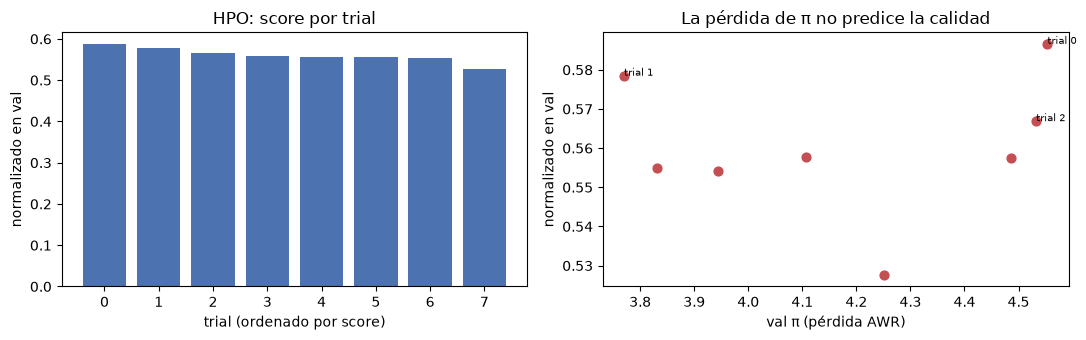

Mejor configuración de arquitectura:


,0
d_model,128.000000
n_heads,4.000000
n_layers,2.000000
dropout,0.000000
lr,0.000538
weight_decay,0.100000
batch_size,512.000000
epochs,10.000000
tau,0.900000
beta,3.000000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(np.arange(len(hpo)), hpo["score"], color="#4c72b0")
axes[0].set_xlabel("trial (ordenado por score)")
axes[0].set_ylabel("normalizado en val")
axes[0].set_title("HPO: score por trial")

axes[1].scatter(hpo["val_pi"], hpo["score"], s=40, color="#c44e52")
axes[1].set_xlabel("val π (pérdida AWR)")
axes[1].set_ylabel("normalizado en val")
axes[1].set_title("La pérdida de π no predice la calidad")
for idx, row in hpo.head(3).iterrows():
    axes[1].annotate(f"trial {idx}", (row["val_pi"], row["score"]), fontsize=7)
plt.tight_layout()
plt.show()

print("Mejor configuración de arquitectura:")
display(hpo.head(1).T)

## 2. Grilla τ, β y γ sobre la mejor arquitectura

Se entrena una vez por cada combinación de τ ∈ {0,7; 0,9}, β ∈ {3; 10} y γ ∈ {0; 0,9}, con la arquitectura ganadora y `group_dropout=0,3`. Para cada configuración se evalúan **π** y **máximo de Q** en validación (warm-up 0, visible/oculto).

La configuración final se elige por el **normalizado medio de ambas políticas y condiciones**, no por las pérdidas. La tabla y el gráfico por γ muestran qué parte del valor viene de la secuencia (γ=0 vs γ>0).

In [7]:
best = hpo.iloc[0]
integer_keys = {"d_model", "n_heads", "n_layers", "batch_size", "epochs"}
best_model_cfg = {
    key: int(best[key]) if key in integer_keys else float(best[key])
    for key in ["d_model", "n_heads", "n_layers", "dropout", "lr",
                "weight_decay", "batch_size", "epochs"]
}
print("Arquitectura elegida:", best_model_cfg)

grid_rows = []
for tau in GRID_TAU:
    for beta in GRID_BETA:
        for gamma in GRID_GAMMA:
            iql_cfg = {"tau": float(tau), "beta": float(beta), "gamma": float(gamma)}
            start = time.time()
            model, history = train_iql(
                train_ep, val_ep, N_ITEMS,
                seed=0,
                max_batches=MAX_BATCHES,
                device=DEVICE,
                amp=USE_AMP,
                verbose=False,
                **best_model_cfg, **FIXED_TRAIN, **iql_cfg,
            )
            raw = eval_iql(model, hpo_users, HPO_CONDITIONS, seeds=(0,))
            summary = summarize(raw, by=["mode", "warmup", "group_visible"])
            norm = summary[("normalized", "mean")]
            pi_score = float(norm.xs("pi", level="mode").mean())
            q_score = float(norm.xs("q", level="mode").mean())
            grid_rows.append({
                **iql_cfg, "pi": pi_score, "q": q_score,
                "score": (pi_score + q_score) / 2,
                "val_pi": float(history.iloc[-1]["val_pi"]),
                "minutos": (time.time() - start) / 60,
            })
            print(
                f"tau={tau} beta={beta} gamma={gamma}: "
                f"pi={pi_score:.3f} q={q_score:.3f} ({grid_rows[-1]['minutos']:.1f} min)"
            )
            del model
            if DEVICE == "cuda":
                torch.cuda.empty_cache()

grid = pd.DataFrame(grid_rows).sort_values("score", ascending=False).reset_index(drop=True)
grid.to_csv(paths / "grid_iql.csv", index=False)
grid.round(4)

Arquitectura elegida: {'d_model': 128, 'n_heads': 4, 'n_layers': 2, 'dropout': 0.0, 'lr': 0.0005379624172736717, 'weight_decay': 0.1, 'batch_size': 512, 'epochs': 10}
tau=0.7 beta=3.0 gamma=0.0: pi=0.583 q=0.597 (1.3 min)
tau=0.7 beta=3.0 gamma=0.9: pi=0.593 q=0.592 (3.1 min)
tau=0.7 beta=10.0 gamma=0.0: pi=0.584 q=0.600 (1.4 min)
tau=0.7 beta=10.0 gamma=0.9: pi=0.589 q=0.595 (2.5 min)


/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


tau=0.9 beta=3.0 gamma=0.0: pi=0.583 q=0.598 (1.6 min)


/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


tau=0.9 beta=3.0 gamma=0.9: pi=0.590 q=0.583 (2.9 min)


/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


tau=0.9 beta=10.0 gamma=0.0: pi=0.583 q=0.601 (2.0 min)


/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


tau=0.9 beta=10.0 gamma=0.9: pi=0.579 q=0.587 (2.1 min)


,tau,beta,gamma,pi,q,score,val_pi,minutos
0,0.7,3.0,0.9,0.5931,0.5919,0.5925,7.6522,3.0602
1,0.9,10.0,0.0,0.5828,0.6014,0.5921,12.1061,1.9534
2,0.7,10.0,0.9,0.5893,0.5945,0.5919,56.5812,2.5111
3,0.7,10.0,0.0,0.5835,0.6000,0.5917,49.6538,1.3876
4,0.9,3.0,0.0,0.5833,0.5983,0.5908,4.3154,1.6199
5,0.7,3.0,0.0,0.5834,0.5972,0.5903,7.3324,1.3390
6,0.9,3.0,0.9,0.5903,0.5829,0.5866,4.5535,2.8749
7,0.9,10.0,0.9,0.5786,0.5871,0.5829,15.4324,2.1289


Configuración IQL elegida: {'tau': 0.7, 'beta': 3.0, 'gamma': 0.9}
Grilla completa (normalizado medio):


,tau,beta,gamma,pi,q,score,val_pi,minutos
0,0.7,3.0,0.9,0.593,0.592,0.593,7.652,3.060
1,0.9,10.0,0.0,0.583,0.601,0.592,12.106,1.953
2,0.7,10.0,0.9,0.589,0.595,0.592,56.581,2.511
3,0.7,10.0,0.0,0.584,0.600,0.592,49.654,1.388
4,0.9,3.0,0.0,0.583,0.598,0.591,4.315,1.620
5,0.7,3.0,0.0,0.583,0.597,0.590,7.332,1.339
6,0.9,3.0,0.9,0.590,0.583,0.587,4.553,2.875
7,0.9,10.0,0.9,0.579,0.587,0.583,15.432,2.129


γ=0 frente a γ>0 (media sobre τ, β y condiciones):


,pi,q,score
gamma,,,
0.0,0.583,0.599,0.591
0.9,0.588,0.589,0.588


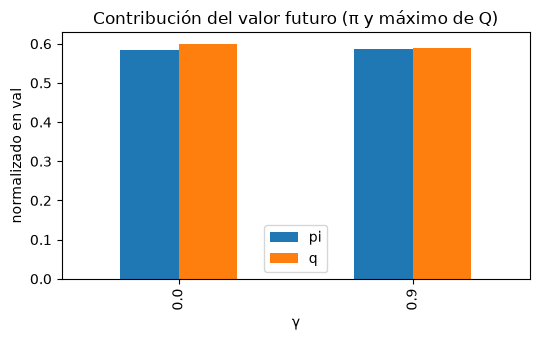

In [8]:
best_grid = grid.iloc[0]
best_iql_cfg = {
    "tau": float(best_grid["tau"]),
    "beta": float(best_grid["beta"]),
    "gamma": float(best_grid["gamma"]),
}
print("Configuración IQL elegida:", best_iql_cfg)

print("Grilla completa (normalizado medio):")
display(grid.round(3))

gamma_view = grid.groupby("gamma")[["pi", "q", "score"]].mean()
print("γ=0 frente a γ>0 (media sobre τ, β y condiciones):")
display(gamma_view.round(3))

fig, ax = plt.subplots(figsize=(5.5, 3.5))
gamma_view[["pi", "q"]].plot.bar(ax=ax)
ax.set_xlabel("γ")
ax.set_ylabel("normalizado en val")
ax.set_title("Contribución del valor futuro (π y máximo de Q)")
plt.tight_layout()
plt.show()

## 3. Entrenamiento final con 3 semillas

Se entrena la configuración elegida con 3 semillas. Cada semilla guarda `modelo_iql.pt`, `config.json` e `historial.csv` en `outputs/<RUN_NAME>/final/seed<k>/`. El checkpoint es el de la última época: en IQL las pérdidas de Q y π pueden subir mientras la política mejora.

In [9]:
models, histories = {}, {}
for seed in FINAL_SEEDS:
    model, history = train_iql(
        train_ep, val_ep, N_ITEMS,
        seed=seed,
        max_batches=MAX_BATCHES,
        device=DEVICE,
        amp=USE_AMP,
        output=paths / "final" / f"seed{seed}",
        **best_model_cfg, **FIXED_TRAIN, **best_iql_cfg,
    )
    models[seed] = model
    histories[seed] = history

epoch   1/10 | V 0.1366 Q 0.6235 π 13.9214 | peso medio 2.18 (truncado 0.1%) | val π 9.1867
epoch   2/10 | V 0.0621 Q 0.3183 π 7.7380 | peso medio 1.26 (truncado 0.0%) | val π 6.8194
epoch   3/10 | V 0.0454 Q 0.2926 π 7.0019 | peso medio 1.12 (truncado 0.0%) | val π 7.8801
epoch   4/10 | V 0.0528 Q 0.2978 π 7.4304 | peso medio 1.20 (truncado 0.0%) | val π 6.6909
epoch   5/10 | V 0.0551 Q 0.2833 π 7.2086 | peso medio 1.17 (truncado 0.0%) | val π 7.1067
epoch   6/10 | V 0.0586 Q 0.2869 π 7.3047 | peso medio 1.18 (truncado 0.0%) | val π 6.9786
epoch   7/10 | V 0.0606 Q 0.2917 π 7.3565 | peso medio 1.20 (truncado 0.0%) | val π 7.7951
epoch   8/10 | V 0.0617 Q 0.2970 π 7.3917 | peso medio 1.20 (truncado 0.0%) | val π 7.3339
epoch   9/10 | V 0.0625 Q 0.3015 π 7.4134 | peso medio 1.21 (truncado 0.0%) | val π 7.5718
epoch  10/10 | V 0.0631 Q 0.3081 π 7.4565 | peso medio 1.21 (truncado 0.0%) | val π 7.6522
checkpoint e historial en outputs/iql_gpu_random/final/seed0
epoch   1/10 | V 0.1403 Q 0.

/home/eluduena/diplo/AprendizajePorRefuerzos/2026/tp/modelos/iql.py:320: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch   1/10 | V 0.1235 Q 0.5609 π 14.1065 | peso medio 2.20 (truncado 0.1%) | val π 8.6406
epoch   2/10 | V 0.0573 Q 0.3143 π 7.6440 | peso medio 1.25 (truncado 0.0%) | val π 7.2500
epoch   3/10 | V 0.0450 Q 0.2983 π 7.0252 | peso medio 1.12 (truncado 0.0%) | val π 6.2870
epoch   4/10 | V 0.0490 Q 0.2830 π 7.0528 | peso medio 1.13 (truncado 0.0%) | val π 6.8620
epoch   5/10 | V 0.0549 Q 0.2831 π 7.2142 | peso medio 1.17 (truncado 0.0%) | val π 6.3685
epoch   6/10 | V 0.0584 Q 0.2864 π 7.2922 | peso medio 1.18 (truncado 0.0%) | val π 6.7002
epoch   7/10 | V 0.0605 Q 0.2906 π 7.3502 | peso medio 1.19 (truncado 0.0%) | val π 7.2236
epoch   8/10 | V 0.0617 Q 0.2949 π 7.3851 | peso medio 1.20 (truncado 0.0%) | val π 7.2963
epoch   9/10 | V 0.0626 Q 0.3008 π 7.4072 | peso medio 1.21 (truncado 0.0%) | val π 7.5798
epoch  10/10 | V 0.0634 Q 0.3098 π 7.4727 | peso medio 1.22 (truncado 0.0%) | val π 7.6516
checkpoint e historial en outputs/iql_gpu_random/final/seed2


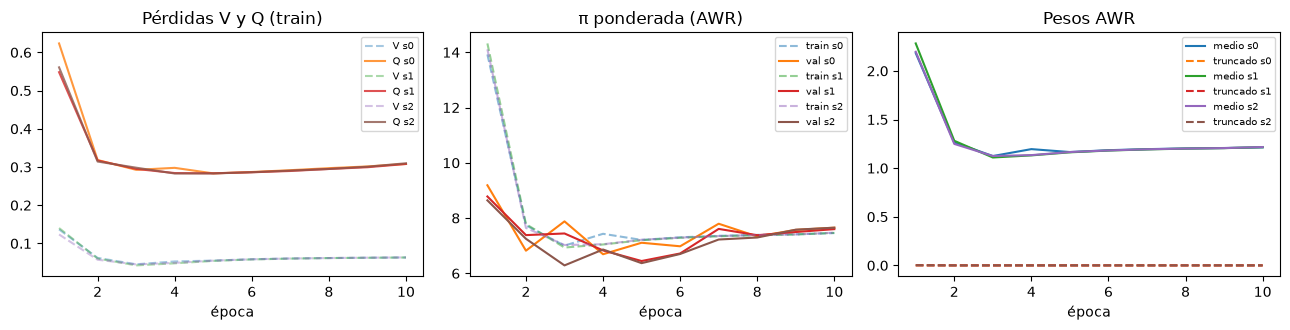

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for seed, history in histories.items():
    axes[0].plot(history["epoch"], history["train_v"], "--", alpha=0.4, label=f"V s{seed}")
    axes[0].plot(history["epoch"], history["train_q"], "-", alpha=0.8, label=f"Q s{seed}")
    axes[1].plot(history["epoch"], history["train_pi"], "--", alpha=0.5, label=f"train s{seed}")
    axes[1].plot(history["epoch"], history["val_pi"], "-", label=f"val s{seed}")
    axes[2].plot(history["epoch"], history["w_medio"], label=f"medio s{seed}")
    axes[2].plot(history["epoch"], history["w_truncado"], "--", label=f"truncado s{seed}")
axes[0].set_title("Pérdidas V y Q (train)")
axes[1].set_title("π ponderada (AWR)")
axes[2].set_title("Pesos AWR")
for axis in axes:
    axis.set_xlabel("época")
    axis.legend(fontsize=7)
plt.tight_layout()
plt.show()

## 4. Evaluación en validación

Se evalúan π y máximo de Q en las 4 condiciones (warm-up 0/5 × grupo visible/oculto) con las 3 semillas de entrenamiento y 3 semillas de evaluación. Se reportan media, IC 95 % por usuario, hit rate y NDCG@10, más el desvío entre semillas de entrenamiento (separado del IC). También se evalúan las líneas base ajustadas con los mismos logs y, si `LOGS != "random"`, el sistema anterior con ε=0.

In [11]:
conditions = [(0, True), (0, False), (5, True), (5, False)]

frames = []
for seed, model in models.items():
    df = eval_iql(model, final_users, conditions, EVAL_SEEDS)
    df["train_seed"] = seed
    frames.append(df)
val_raw = pd.concat(frames, ignore_index=True)
val_raw.to_csv(paths / "iql_val_sesiones.csv", index=False)

val_summary = summarize(val_raw, by=["mode", "warmup", "group_visible"])
norm = val_summary[("normalized", "mean")]
table = pd.concat({
    "normalized": norm,
    "ci95": val_summary[("normalized", "ci95")],
    "hit_rate": val_summary[("hit_rate", "mean")],
    "ndcg@10": val_summary[("ndcg@10", "mean")],
}, axis=1)
print("Validación: media e IC 95 % por usuario")
display(table.round(3))

seed_stats = (
    val_raw.groupby(["mode", "warmup", "group_visible", "train_seed"])["normalized"].mean()
    .groupby(["mode", "warmup", "group_visible"]).agg(["mean", "std"]).round(3)
)
print("Media y desvío entre semillas de entrenamiento")
display(seed_stats)

Validación: media e IC 95 % por usuario


normalized   ci95  hit_rate  ndcg@10
mode warmup group_visible                                      
pi   0      False               0.564  0.012     0.747    0.841
            True                0.642  0.011     0.794    0.871
     5      False               0.586  0.013     0.774    0.841
            True                0.651  0.011     0.816    0.874
q    0      False               0.555  0.011     0.742    0.841
            True                0.646  0.011     0.796    0.873
     5      False               0.584  0.012     0.774    0.841
            True                0.655  0.011     0.817    0.875

Media y desvío entre semillas de entrenamiento


mean    std
mode warmup group_visible              
pi   0      False          0.564  0.004
            True           0.642  0.005
     5      False          0.586  0.002
            True           0.651  0.004
q    0      False          0.555  0.002
            True           0.646  0.002
     5      False          0.584  0.005
            True           0.655  0.005

In [12]:
factories = baseline_factories(baseline_train, N_ITEMS)
if LOGS != "random":
    _, temperature = PRESETS[LOGS]
    factories["sistema_anterior_eps0"] = lambda: PreviousSystem.fit(
        train, N_ITEMS, 0.0, temperature, np.random.default_rng(0)
    )

base_frames = []
for name, factory in factories.items():
    df = eval_policy(factory(), final_users, conditions, EVAL_SEEDS)
    df["policy"] = name
    base_frames.append(df)
base_raw = pd.concat(base_frames, ignore_index=True)
base_summary = summarize(base_raw, by=["policy", "warmup", "group_visible"])
base_norm = base_summary[("normalized", "mean")]

comparison = base_norm.unstack(["warmup", "group_visible"])
for mode in ("pi", "q"):
    comparison.loc[f"iql_{mode}"] = norm.xs(mode, level="mode")
print("Comparación en validación (normalizado, 0=azar, 1=oráculo):")
display(comparison.round(3))

Comparación en validación (normalizado, 0=azar, 1=oráculo):


warmup               0             5       
group_visible    False  True   False  True 
policy                                     
group_mean       0.565  0.656  0.580  0.666
group_posterior  0.617  0.656  0.640  0.666
item_mean        0.565  0.565  0.580  0.580
popularity      -0.028 -0.028 -0.020 -0.020
random           0.009  0.005 -0.006 -0.005
iql_pi           0.564  0.642  0.586  0.651
iql_q            0.555  0.646  0.584  0.655

In [13]:
per_group = summarize(
    val_raw, by=["mode", "warmup", "group_visible", "group"]
)[("normalized", "mean")]
per_group_table = per_group.unstack("group")
print("Resultados por grupo (normalizado):")
display(per_group_table.round(3))

Resultados por grupo (normalizado):


group                          0      1      2      3      4      5      6  \
mode warmup group_visible                                                    
pi   0      False          0.641  0.586  0.582  0.496  0.634  0.487  0.600   
            True           0.673  0.675  0.611  0.605  0.653  0.686  0.672   
     5      False          0.659  0.614  0.586  0.506  0.639  0.565  0.609   
            True           0.688  0.678  0.618  0.593  0.661  0.704  0.685   
q    0      False          0.608  0.577  0.567  0.506  0.635  0.498  0.564   
            True           0.677  0.682  0.615  0.611  0.648  0.685  0.677   
     5      False          0.647  0.622  0.573  0.511  0.634  0.572  0.591   
            True           0.701  0.693  0.618  0.597  0.659  0.699  0.681   

group                          7  
mode warmup group_visible         
pi   0      False          0.482  
            True           0.564  
     5      False          0.513  
            True           0.580  
q    0      False          0.487  
            True           0.573  
     5      False          0.524  
            True           0.589

## 5. Test reservado

`RUN_TEST = False` por defecto: test se usa **una sola vez**, cuando la configuración, γ, τ, β y las semillas ya están congelados en validación. Al ponerlo en `True`, evalúa las 3 semillas de entrenamiento (π y máximo de Q) y las líneas base con los mismos logs, y escribe `sesiones.csv`, `resumen.csv` y `resumen_por_grupo.csv`.

In [14]:
if RUN_TEST:
    test_users = load_test(DATASET)
    test_frames = []
    for seed, model in models.items():
        df = eval_iql(model, test_users, conditions, EVAL_SEEDS)
        df["policy"] = df["mode"].map(lambda mode: f"iql_{mode}_seed{seed}")
        test_frames.append(df)
    for name, factory in factories.items():
        df = eval_policy(factory(), test_users, conditions, EVAL_SEEDS)
        df["policy"] = name
        test_frames.append(df)
    test_raw = pd.concat(test_frames, ignore_index=True)
    write_reports(test_raw, paths / "eval" / "test")
else:
    print("RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.")

RUN_TEST=False: test reservado. Cambiarlo a True una sola vez, al final.


## Checklist antes de la entrega

- [ ] La arquitectura y τ, β, γ se eligieron **sólo con validación**.
- [ ] Se reportan 3 semillas de entrenamiento: media y desvío entre semillas, separados del IC 95 % por usuario.
- [ ] Las líneas base se ajustaron con los **mismos logs** que el modelo.
- [ ] Están las dos políticas: π (AWR) y máximo de Q, con la comparación γ=0 vs γ>0.
- [ ] Están los resultados por grupo y las métricas secundarias (hit rate, NDCG@10).
- [ ] Si se usa `mixto`, se repitió todo con `LOGS = "mixto"` y se reajustaron las líneas base con esos logs.
- [ ] `RUN_TEST = True` se usó una sola vez, al final.